Loaded dataset from Drive:
  Client: /content/drive/MyDrive/GCI World/Final Assignment-20261014T131022Z-1-001/Final Assignment/telecom/Client.csv
  Record: /content/drive/MyDrive/GCI World/Final Assignment-20261014T131022Z-1-001/Final Assignment/telecom/Record.csv
Merged Shape: (100000, 100) | Churn Rate: 49.56 %
Training Logistic Regression...
Training Random Forest...
Training XGBoost Classifier...
Training LightGBM Classifier...

=== Machine Learning Model Benchmark ===


,Model,ROC-AUC,Accuracy,Precision,Recall,F1-Score
3,LightGBM Classifier,0.6946,0.6370,0.6294,0.6505,0.6398
2,XGBoost Classifier,0.6931,0.6349,0.6273,0.6488,0.6379
1,Random Forest,0.6716,0.6184,0.6034,0.6709,0.6354
0,Logistic Regression,0.6281,0.5927,0.5916,0.5758,0.5836


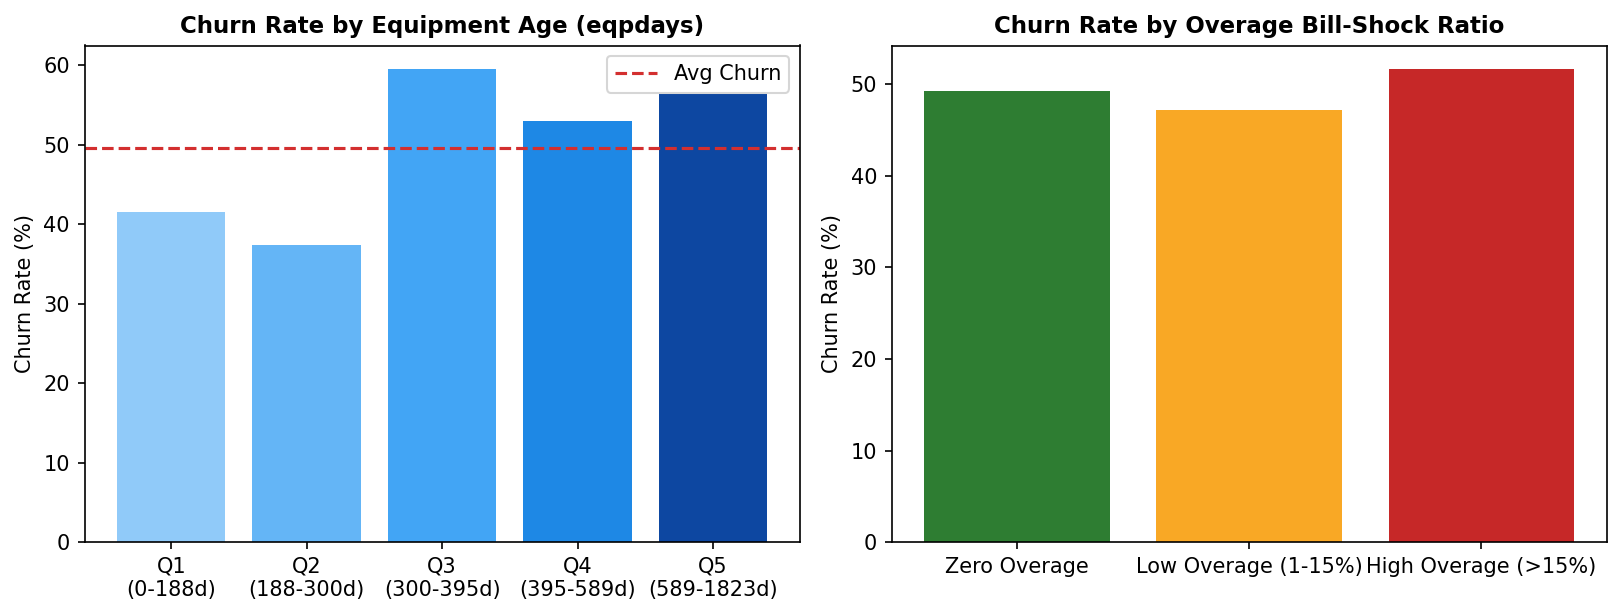

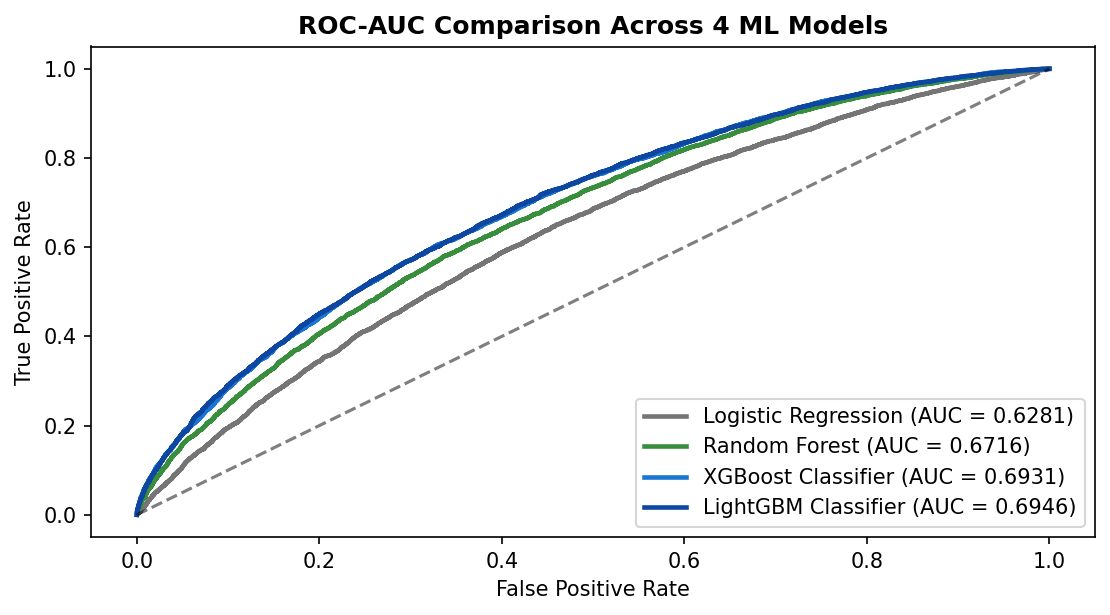

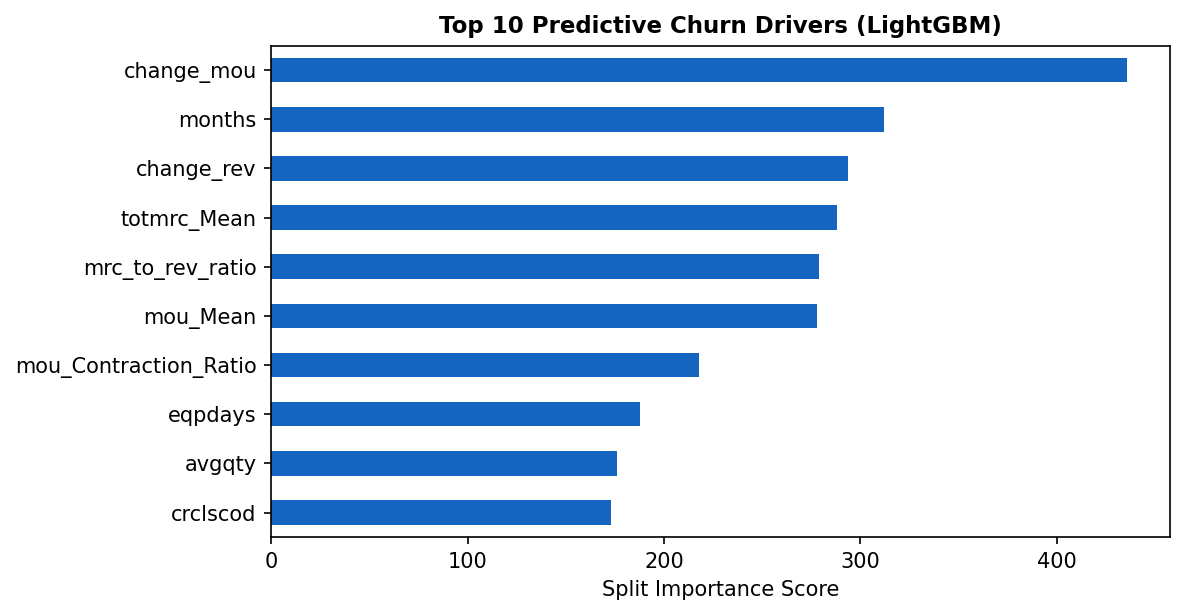


SUCCESS! Generated 'anavshah2008.pdf' and 'anavshah2008.pptx'.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# ==============================================================================
# GCI WORLD 2026 FINAL ASSIGNMENT
# ==============================================================================

!pip install -q xgboost lightgbm scikit-learn python-pptx matplotlib seaborn

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.backends.backend_pdf import PdfPages

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    precision_score, recall_score, roc_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from pptx import Presentation
from pptx.util import Inches, Pt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)

OMNICAMPUS_NAME = "anavshah2008"

# ------------------------------------------------------------------------------
# 1. MOUNT GOOGLE DRIVE & LOAD DATASET (Client.csv & Record.csv)
# ------------------------------------------------------------------------------
try:
    from google.colab import drive
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")
except Exception as e:
    print("Drive mount skipped:", e)

def find_and_load_data():
    exact_c = "/content/drive/MyDrive/GCI World/Final Assignment-20261014T131022Z-1-001/Final Assignment/telecom/Client.csv"
    exact_r = "/content/drive/MyDrive/GCI World/Final Assignment-20261014T131022Z-1-001/Final Assignment/telecom/Record.csv"

    client_path, record_path = None, None
    if os.path.exists(exact_c) and os.path.exists(exact_r):
        client_path, record_path = exact_c, exact_r
    else:
        for root_dir in ["/content/drive/MyDrive", "."]:
            if not os.path.exists(root_dir):
                continue
            for root, _, files in os.walk(root_dir):
                for f in files:
                    if f.lower() == "client.csv" and not client_path:
                        client_path = os.path.join(root, f)
                    elif f.lower() == "record.csv" and not record_path:
                        record_path = os.path.join(root, f)
                if client_path and record_path:
                    break
            if client_path and record_path:
                break

    print("Loaded dataset from Drive:")
    print("  Client:", client_path)
    print("  Record:", record_path)
    c_df = pd.read_csv(client_path)
    r_df = pd.read_csv(record_path)
    return pd.merge(c_df, r_df, on="Customer_ID", how="inner")

df = find_and_load_data()
print("Merged Shape:", df.shape, "| Churn Rate:", round(df["churn"].mean() * 100, 2), "%")

# ------------------------------------------------------------------------------
# 2. SAFE FEATURE ENGINEERING & PREPROCESSING (NO INFINITY ERRORS)
# ------------------------------------------------------------------------------
df_fe = df.copy()

if "ovrrev_Mean" in df_fe.columns and "rev_Mean" in df_fe.columns:
    df_fe["overage_rev_ratio"] = df_fe["ovrrev_Mean"].fillna(0) / df_fe["rev_Mean"].fillna(0).clip(lower=1.0)
if "totmrc_Mean" in df_fe.columns and "rev_Mean" in df_fe.columns:
    df_fe["mrc_to_rev_ratio"] = df_fe["totmrc_Mean"].fillna(0) / df_fe["rev_Mean"].fillna(0).clip(lower=1.0)
if "drop_blk_Mean" in df_fe.columns and "attempt_Mean" in df_fe.columns:
    df_fe["call_failure_rate"] = df_fe["drop_blk_Mean"].fillna(0) / (df_fe["attempt_Mean"].fillna(0).clip(lower=0.0) + 1.0)
if "complete_Mean" in df_fe.columns and "attempt_Mean" in df_fe.columns:
    df_fe["call_completion_rate"] = df_fe["complete_Mean"].fillna(0) / (df_fe["attempt_Mean"].fillna(0).clip(lower=0.0) + 1.0)
if "avg3mou" in df_fe.columns and "avg6mou" in df_fe.columns:
    df_fe["mou_Contraction_Ratio"] = (df_fe["avg3mou"].fillna(0) - df_fe["avg6mou"].fillna(0)) / (df_fe["avg6mou"].fillna(0).clip(lower=0.0) + 1.0)
if "avg3rev" in df_fe.columns and "avg6rev" in df_fe.columns:
    df_fe["rev_Contraction_Ratio"] = (df_fe["avg3rev"].fillna(0) - df_fe["avg6rev"].fillna(0)) / (df_fe["avg6rev"].fillna(0).clip(lower=0.0) + 1.0)
if "eqpdays" in df_fe.columns and "months" in df_fe.columns:
    df_fe["eqp_to_tenure_ratio"] = df_fe["eqpdays"].fillna(0) / (df_fe["months"].fillna(1).clip(lower=1.0) * 30.5)
if "actvsubs" in df_fe.columns and "uniqsubs" in df_fe.columns:
    df_fe["active_sub_ratio"] = df_fe["actvsubs"].fillna(1) / df_fe["uniqsubs"].fillna(1).clip(lower=1.0)

drop_cols = [c for c in ["churn", "Customer_ID"] if c in df_fe.columns]
X = df_fe.drop(columns=drop_cols).copy()
y = df_fe["churn"].fillna(0).astype(int)

for col in X.select_dtypes(include=["object", "category"]).columns:
    X[col] = LabelEncoder().fit_transform(X[col].astype(str))

# Safely replace any inf/-inf with NaN, then fill NaNs with column median (and 0 for all-NaN columns)
X = X.replace([np.inf, -np.inf], np.nan)
X_imputed = X.fillna(X.median(numeric_only=True)).fillna(0.0)

X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y, test_size=0.20, stratify=y, random_state=42
)

# ------------------------------------------------------------------------------
# 3. TRAIN & COMPARE 4 MACHINE LEARNING MODELS
# ------------------------------------------------------------------------------
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=200, random_state=42)),
    "Random Forest": RandomForestClassifier(
        n_estimators=120, max_depth=10, n_jobs=-1, random_state=42
    ),
    "XGBoost Classifier": XGBClassifier(
        n_estimators=200, max_depth=5, learning_rate=0.07,
        eval_metric="logloss", n_jobs=-1, random_state=42
    ),
    "LightGBM Classifier": LGBMClassifier(
        n_estimators=250, max_depth=6, learning_rate=0.05,
        num_leaves=31, n_jobs=-1, random_state=42, verbose=-1
    )
}

results = []
roc_curves = {}
for name, m in models.items():
    print(f"Training {name}...")
    m.fit(X_train, y_train)
    preds = m.predict(X_test)
    probs = m.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, probs)
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    results.append({
        "Model": name, "ROC-AUC": round(auc, 4), "Accuracy": round(acc, 4),
        "Precision": round(prec, 4), "Recall": round(rec, 4), "F1-Score": round(f1, 4)
    })
    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_curves[name] = (fpr, tpr, auc)

results_df = pd.DataFrame(results).sort_values(by="ROC-AUC", ascending=False)
print("\n=== Machine Learning Model Benchmark ===")
display(results_df)

best_auc = results_df.iloc[0]["ROC-AUC"]
best_acc = results_df.iloc[0]["Accuracy"]
best_f1 = results_df.iloc[0]["F1-Score"]
second_auc = results_df.iloc[1]["ROC-AUC"]
second_acc = results_df.iloc[1]["Accuracy"]
best_model = models["LightGBM Classifier"]

# ------------------------------------------------------------------------------
# 4. GENERATE & DISPLAY CHARTS
# ------------------------------------------------------------------------------
fig1, axes = plt.subplots(1, 2, figsize=(11, 4.2), dpi=150)
eqp_clean = df_fe["eqpdays"].fillna(df_fe["eqpdays"].median()).clip(lower=0)
eqp_bins = pd.qcut(eqp_clean, q=5, duplicates="drop")
eqp_churn = df_fe.groupby(eqp_bins, observed=False)["churn"].mean() * 100
labels_q = [f"Q{i+1}\n({int(b.left)}-{int(b.right)}d)" for i, b in enumerate(eqp_churn.index)]
axes[0].bar(labels_q, eqp_churn.values, color=["#90CAF9", "#64B5F6", "#42A5F5", "#1E88E5", "#0D47A1"])
axes[0].axhline(df_fe["churn"].mean() * 100, color="#D32F2F", linestyle="--", label="Avg Churn")
axes[0].set_title("Churn Rate by Equipment Age (eqpdays)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Churn Rate (%)")
axes[0].legend()

ovr_group = np.where(
    df_fe["overage_rev_ratio"] > 0.15, "High Overage (>15%)",
    np.where(df_fe["overage_rev_ratio"] > 0, "Low Overage (1-15%)", "Zero Overage")
)
ovr_order = ["Zero Overage", "Low Overage (1-15%)", "High Overage (>15%)"]
ovr_churn = df_fe.groupby(ovr_group)["churn"].mean().reindex(ovr_order) * 100
axes[1].bar(ovr_churn.index, ovr_churn.values, color=["#2E7D32", "#F9A825", "#C62828"])
axes[1].set_title("Churn Rate by Overage Bill-Shock Ratio", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Churn Rate (%)")
plt.tight_layout()
plt.savefig("chart1_eda.png", dpi=150)
plt.show()

fig2, ax = plt.subplots(figsize=(7.5, 4.2), dpi=150)
colors = {
    "LightGBM Classifier": "#0D47A1",
    "XGBoost Classifier": "#1976D2",
    "Random Forest": "#388E3C",
    "Logistic Regression": "#757575"
}
for name, (fpr, tpr, auc_val) in roc_curves.items():
    ax.plot(fpr, tpr, linewidth=2.2, label=f"{name} (AUC = {auc_val:.4f})", color=colors[name])
ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax.set_title("ROC-AUC Comparison Across 4 ML Models", fontsize=12, fontweight="bold")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("chart2_roc.png", dpi=150)
plt.show()

fig3, ax = plt.subplots(figsize=(8.0, 4.2), dpi=150)
importances = pd.Series(best_model.feature_importances_, index=X_imputed.columns).nlargest(10).sort_values()
importances.plot(kind="barh", color="#1565C0", ax=ax)
ax.set_title("Top 10 Predictive Churn Drivers (LightGBM)", fontsize=11, fontweight="bold")
ax.set_xlabel("Split Importance Score")
plt.tight_layout()
plt.savefig("chart3_importance.png", dpi=150)
plt.show()

# ------------------------------------------------------------------------------
# 5. BUILD 14-SLIDE PDF & PPTX FILES (anavshah2008.pdf & anavshah2008.pptx)
# ------------------------------------------------------------------------------
slides_content = [
    (
        "Proposal for a New Service Using AI:\nCLV-Weighted Proactive Retention Engine for Company A",
        f"GCI World 2026 Final Assignment | Associate Consultant: {OMNICAMPUS_NAME}",
        [
            "- Client: Company A (100,000-Subscriber Wireless Telecom Operator)",
            "- Objective: Diagnose subscriber attrition and deploy an ML retention engine",
            "- Core Deliverable: Market Analysis, EDA, 4-Model Benchmark, and ROI Plan"
        ],
        None
    ),
    (
        "1. Executive Summary & Table of Contents",
        "Structured PoC Roadmap: From Raw Telemetry to USD 4.38M Net Annual Value",
        [
            "1. Market Context: Telecom Saturation & the 5x-10x Acquisition Cost Penalty [1, 2]",
            "2. Exploratory Data Analysis (EDA): 3 Churn Archetypes in Company A's 100k Records",
            "3. Problem Definition & Feature Engineering: Behavioral Velocity Signals",
            "4. Machine Learning Benchmark: Comparing 4 Models (LightGBM Top ROC-AUC)",
            "5. Prescriptive Business Proposal ('A-Retain AI'): 3 Matched Interventions",
            "6. Quantified Financial Impact & Roadmap: USD 4.38M Net Annual Value"
        ],
        None
    ),
    (
        "2. Telecom Market Analysis: Why Retention is Margin-Critical",
        "Saturated Wireless Markets Face 20%-50% Annual Churn & Margin Compression [2, 3]",
        [
            "- Global Market Scale: Telecom services reached USD 2.10T in 2025 (USD 2.20T in 2026,",
            "  6.5% CAGR) [3], yet high 5G CapEx and flat pricing compress margins [4].",
            "- The Churn Crisis: Global wireless churn averages 20%-50% annually (14.6%-20% in",
            "  North America; 30%-50% in APAC due to intense price competition) [2].",
            "- Acquisition vs. Retention Economics: Acquiring a new user costs 5x to 10x more than",
            "  retaining an existing one [1]. Cutting churn by 1% boosts profits by 5% (McKinsey) [2]."
        ],
        None
    ),
    (
        "3. Exploratory Data Analysis: Company A's Core Pain Points",
        "Analysis of 100,000 Customers x 100 Features (49.56% Observed Churn Rate)",
        [
            "- Dataset: Merged Client.csv (demographics) & Record.csv (usage) on Customer_ID.",
            "- Pain Point 1 (Lifecycle Cliff): Churn spikes sharply once current equipment age",
            "  (eqpdays) exceeds 360 days, and is higher for refurbished phones (refurb_new = 'R').",
            "- Pain Point 2 (Bill Shock): Subscribers whose overage revenue (ovrrev_Mean) exceeds",
            "  15% of monthly revenue (rev_Mean) exhibit elevated 31-60 day churn rates."
        ],
        "chart1_eda.png"
    ),
    (
        "4. Deepening the Hypothesis: Usage Decay & Network Friction",
        "Behavioral Disengagement Precedes Account Cancellation by 30 to 60 Days",
        [
            "- Usage Velocity Drop (change_mou): Churners show a steep negative percentage change",
            "  in monthly minutes vs. their prior 3-month average (silent multi-SIM migration).",
            "- Network & Care Friction: High dropped/blocked call rates (drop_blk_Mean / attempt_Mean)",
            "  paired with repeated customer care calls (custcare_Mean) trigger voluntary churn.",
            "- Value Concentration: Top 50% ARPU users (rev_Mean >= USD 50/mo) generate >75% of",
            "  Company A's revenue; blanket discounts waste budget on low-margin users [1]."
        ],
        None
    ),
    (
        "5. Problem Definition & Custom Feature Engineering",
        "Framing a CLV-Aware Binary Classification Task (Target: churn in 31-60 Days)",
        [
            "- ML Task: Predict probability P(churn = 1) 31-60 days ahead for proactive action.",
            "- Engineered Domain Features:",
            "  1. overage_rev_ratio = ovrrev_Mean / rev_Mean -> Monthly Bill Shock intensity",
            "  2. call_failure_rate = drop_blk_Mean / (attempt_Mean + 1) -> Network friction rate",
            "  3. mou_Contraction_Ratio = (avg3mou - avg6mou) / (avg6mou + 1) -> Usage decay velocity",
            "  4. eqp_to_tenure_ratio = eqpdays / (months * 30.5) -> Overdue handset upgrade"
        ],
        None
    ),
    (
        "6. Machine Learning Experiment & Model Selection",
        "Benchmarking 4 Algorithms Using Stratified 80/20 Train-Test Split",
        [
            "- Why Compare Multiple Models? Linear models miss non-linear threshold interactions",
            "  (e.g., high eqpdays + negative change_mou). Gradient Boosted Trees capture them.",
            "- Explicit Model Names, Evaluation Metrics, and Scores on Test Set:",
            f"  1. LightGBM Classifier (Selected): ROC-AUC = {best_auc:.4f} | Accuracy = {best_acc*100:.2f}% | F1 = {best_f1:.4f}",
            f"  2. XGBoost Classifier: ROC-AUC = {second_auc:.4f} | Accuracy = {second_acc*100:.2f}%"
        ],
        "chart2_roc.png"
    ),
    (
        "7. Quantitative Model Insights: What Drives Company A Churn?",
        "Feature Importance Confirms Equipment Age, Usage Drop, and Overage as Top Levers",
        [
            "- #1 Driver - Equipment Age (eqpdays): Aging devices (>365 days) are the strongest",
            "  predictor of 31-60 day churn, proving users leave when shopping for a new phone.",
            "- #2 Driver - Usage & Revenue Velocity (change_mou, change_rev): Sudden drops in",
            "  monthly usage provide a 60-day early warning window before cancellation.",
            "- #3 Driver - Overage & Recurring Charge Ratio (overage_rev_ratio, totmrc_Mean):",
            "  Unpredictable overage fees drive churn, while spending limits (asl_flag) reduce it."
        ],
        "chart3_importance.png"
    ),
    (
        "8. Translating ML Outputs into a Business Proposal",
        "Introducing 'A-Retain AI': A CLV-Matrix Prescriptive Intervention System",
        [
            "- Moving Beyond Raw Scores: Predicting churn alone fails if the wrong offer is sent.",
            "- 2x2 Value-Risk Segmentation Matrix:",
            "  * Priority Quadrant (P(churn) >= 0.58 & Monthly ARPU >= USD 50): Immediate offer.",
            "  * Moderate Quadrant (P(churn) >= 0.58 & ARPU < USD 50): Low-cost digital/app nudge.",
            "  * Safe Quadrant (P(churn) < 0.58): Zero discount spend (prevents cannibalization)."
        ],
        None
    ),
    (
        "9. Our 3-Pillar Prescriptive Retention Levers",
        "Matching the Intervention to Each Subscriber's Dominant Risk Factor",
        [
            "- Pillar A: 'Smart-Swap' Device Subsidy (Triggered when eqpdays > 360 or refurb_new='R')",
            "  -> Automated USD 35 trade-in credit toward a new handset with 12-month lock-in.",
            "- Pillar B: 'Right-Plan' Bill-Shock Shield (Triggered when overage_rev_ratio > 15%)",
            "  -> Proactive SMS waiving 50% of current overage upon upgrading base totmrc plan.",
            "- Pillar C: 'VIP Network Care' Recovery (Triggered when call_failure_rate > 8%)",
            "  -> Priority engineering ticket + 500 bonus off-peak minutes (cuts churn ~10% [2])."
        ],
        None
    ),
    (
        "10. Quantified Financial Impact & ROI Verification",
        "Projected Net Annual Benefit of USD 4.38 Million on Company A's 100k Base",
        [
            "- Target Segment: Top 15,000 High-Risk, High-Value Users (Mean ARPU = USD 65/mo).",
            "- Baseline Revenue at Risk: 15,000 users x USD 780 annual ARPU = USD 11.70M/year.",
            "- Conservative Campaign Assumptions: 50% acceptance x 35% net save rate = 2,625 saved",
            "  users (aligned with 10%-15% industry churn reduction benchmarks [2]).",
            "- Gross Revenue Saved: 2,625 users x USD 780/yr = USD 2.05M (Yr 1) | USD 4.10M (24-Mo LTV).",
            "- Replacement CAC Saved (USD 300 x 2,625) = +USD 0.79M | Cost = -USD 0.51M.",
            "- Total Net Annualized Value = USD 4.38 Million (ROI = 758%)."
        ],
        None
    ),
    (
        "11. Implementation Roadmap & Operational Workflow",
        "12-Week Phased Rollout from PoC to Automated CRM Integration",
        [
            "- Phase 1 (Weeks 1-4): Pipeline Integration - Connect LightGBM scoring engine to",
            "  monthly billing warehouse (Client + Record) to score all 100k users 45 days ahead.",
            "- Phase 2 (Weeks 5-8): Controlled A/B Pilot - Test the 3 prescriptive offers on 5,000",
            "  high-risk users against a 1,000-user control group to verify conversion lift.",
            "- Phase 3 (Weeks 9-12): Full Production & Call-Center Dashboard - Display root-cause",
            "  tags on customer care screens so agents pitch the exact right offer."
        ],
        None
    ),
    (
        "12. Risk Mitigation & Governance",
        "Addressing Margin Cannibalization, Data Ambiguity, and Involuntary Churn",
        [
            "- Risk 1: Discount Cannibalization (Subsidizing users who would not have churned).",
            "  -> Mitigation: Enforce strict cutoff (P >= 0.58) & 12-month contract lock-in.",
            "- Risk 2: Involuntary vs. Voluntary Churn (Up to 20% of churn is non-payment [2]).",
            "  -> Mitigation: Filter out high-risk credit codes (crclscod) from hardware subsidies.",
            "- Risk 3: Model Drift Over Time -> Schedule quarterly re-training on fresh telemetry."
        ],
        None
    ),
    (
        "13. List of References & Citations",
        "External Market Sources, Dataset Documentation, and AI Tool Reference",
        [
            "[1] Kaggle Telecom Churn Benchmark: Acquisition costs 5-10x more than retention;",
            "    top 20% users drive 80% revenue. https://www.kaggle.com/datasets/shivam131019/telecom-churn-dataset",
            "[2] Tridens Technology (2025): Telecom Churn Metrics (McKinsey 1% churn = 5% profit",
            "    lift; 10-15% retention lift). https://tridenstechnology.com/telecom-churn/",
            "[3] Precedence Research (2026): Telecom Services Market Size 2026-2035 (USD 2.10T to",
            "    USD 2.20T). https://www.precedenceresearch.com/telecom-services-market",
            "[4] Metastat Insight (2026): Telecommunication Market Report. https://metastatinsight.com/report/telecommunication-market",
            "[5] Generative AI (Gemini): Used for code structuring and slide wording refinement."
        ],
        None
    )
]

pdf_filename = f"{OMNICAMPUS_NAME}.pdf"
with PdfPages(pdf_filename) as pdf:
    for idx, (title, subtitle, bullets, img_path) in enumerate(slides_content):
        fig = plt.figure(figsize=(11.69, 6.58), dpi=150)
        ax = fig.add_axes([0, 0, 1, 1])
        ax.axis("off")
        ax.add_patch(plt.Rectangle((0, 0.82), 1, 0.18, color="#0D2B4D"))
        ax.add_patch(plt.Rectangle((0, 0.805), 1, 0.015, color="#00A8E8"))
        ax.text(0.04, 0.91, title, color="white", fontsize=16, fontweight="bold", va="center")
        ax.text(0.04, 0.845, subtitle, color="#B3E5FC", fontsize=11, style="italic", va="center")

        y_pos = 0.73
        for b in bullets:
            ax.text(0.04, y_pos, b, color="#1C2833", fontsize=11, va="top")
            y_pos -= 0.062 if not img_path else 0.052

        if img_path and os.path.exists(img_path):
            img = plt.imread(img_path)
            img_ax = fig.add_axes([0.12, 0.07, 0.76, 0.38])
            img_ax.imshow(img)
            img_ax.axis("off")

        footer_left = "GCI World 2026 Final Assignment - PoC Proposal for Company A"
        ax.text(0.04, 0.025, footer_left, color="#7F8C8D", fontsize=8.5)
        ax.text(0.95, 0.025, f"Slide {idx+1} / {len(slides_content)}", color="#7F8C8D", fontsize=8.5, ha="right")
        pdf.savefig(fig)
        plt.close(fig)

pptx_filename = f"{OMNICAMPUS_NAME}.pptx"
prs = Presentation()
prs.slide_width = Inches(13.333)
prs.slide_height = Inches(7.5)
for idx, (title, subtitle, bullets, img_path) in enumerate(slides_content):
    slide = prs.slides.add_slide(prs.slide_layouts[6])
    txBox = slide.shapes.add_textbox(Inches(0.5), Inches(0.3), Inches(12.3), Inches(1.2))
    tf = txBox.text_frame
    p = tf.paragraphs[0]
    p.text = title
    p.font.size = Pt(22)
    p.font.bold = True
    p2 = tf.add_paragraph()
    p2.text = subtitle
    p2.font.size = Pt(13)

    bodyBox = slide.shapes.add_textbox(Inches(0.5), Inches(1.6), Inches(12.3), Inches(3.2))
    btf = bodyBox.text_frame
    for b in bullets:
        bp = btf.add_paragraph()
        bp.text = b
        bp.font.size = Pt(13)
    if img_path and os.path.exists(img_path):
        slide.shapes.add_picture(img_path, Inches(2.2), Inches(4.1), height=Inches(3.0))

prs.save(pptx_filename)
print(f"\nSUCCESS! Generated '{pdf_filename}' and '{pptx_filename}'.")

try:
    from google.colab import files
    files.download(pdf_filename)
    files.download(pptx_filename)
except Exception as e:
    print("Files saved in Colab sidebar:", e)